# 04 Style evolution since 2000

How the UFC's style features have changed year by year, using **unadjusted** features: no shrinkage, no standardization, no
eligibility filter. Purely descriptive.

- Each year's value pools all UFC fighter-fights in that year (`features.load_fighter_fights()`, fights since 2000). Shares are
  Σ attempts in a position or target / Σ significant-strike attempts. Rates are Σ attempts / Σ fighter fight time. Control share is
  Σ control time / Σ fighter fight time.
- **95% confidence bands** come from a bootstrap that resamples fights within each year (1,000 resamples; both fighters' rows move
  together). They reflect sampling variability across fights, not uncertainty about the data.
- 2026 is a partial year (data through 2026-08-08).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F

pd.set_option("display.width", 220, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
ff = F.load_fighter_fights()
ff["year"] = ff["event_date"].str[:4].astype(int)
ff["ctrl_time_s"] = np.where(ff["ctrl_s"].notna(), ff["time_s"], 0)
ff["ctrl_s"] = ff["ctrl_s"].fillna(0)
# feature -> (numerator column, denominator column, scale), the same definitions as features.RATIOS
DEFS = {f: F.RATIOS[f] for f in F.STYLE_FEATURES}
UNITS = {"td_att_per15": "attempts per 15 min", "sub_att_per15": "attempts per 15 min", "pace": "sig. attempts per min",
         "ctrl_share": "share of fight time"}
cols = sorted({c for n, d, _ in DEFS.values() for c in (n, d)})
fights = ff.groupby(["year", "fight_id"])[cols].sum().reset_index()   # fight-level sums (both fighters)
print(f"{ff['fight_id'].nunique():,} fights, {len(ff):,} fighter-fights, {ff['year'].min()}-{ff['year'].max()}")
display(ff.groupby("year")["fight_id"].nunique().rename("fights").to_frame().T)

8,596 fights, 17,192 fighter-fights, 2000-2026


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
fights,43,40,53,41,39,80,158,171,201,215,...,457,474,516,456,509,511,520,517,520,326


In [2]:
def yearly(fights, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for year, g in fights.groupby("year"):
        W = rng.multinomial(len(g), np.full(len(g), 1 / len(g)), size=n_boot)   # bootstrap weights over fights
        for f, (num, den, scale) in DEFS.items():
            est = scale * g[num].sum() / g[den].sum()
            boot = scale * (W @ g[num].to_numpy()) / (W @ g[den].to_numpy())
            lo, hi = np.quantile(boot, [0.025, 0.975])
            rows.append({"year": year, "feature": f, "value": est, "lo": lo, "hi": hi, "fights": len(g)})
    return pd.DataFrame(rows)

trend = yearly(fights)
# Composition check: the five men's divisions present throughout 2000-2026
CORE = ["Lightweight", "Welterweight", "Middleweight", "Light Heavyweight", "Heavyweight"]
core_fights = ff[ff["division"].isin(CORE)].groupby(["year", "fight_id"])[cols].sum().reset_index()
trend_core = yearly(core_fights, n_boot=200, seed=1)

## 1. Each style feature by year

Blue: all UFC fights, with 95% band. Grey dashed: only the five men's divisions present throughout (LW, WW, MW, LHW, HW), to show how much of a trend comes from new divisions.

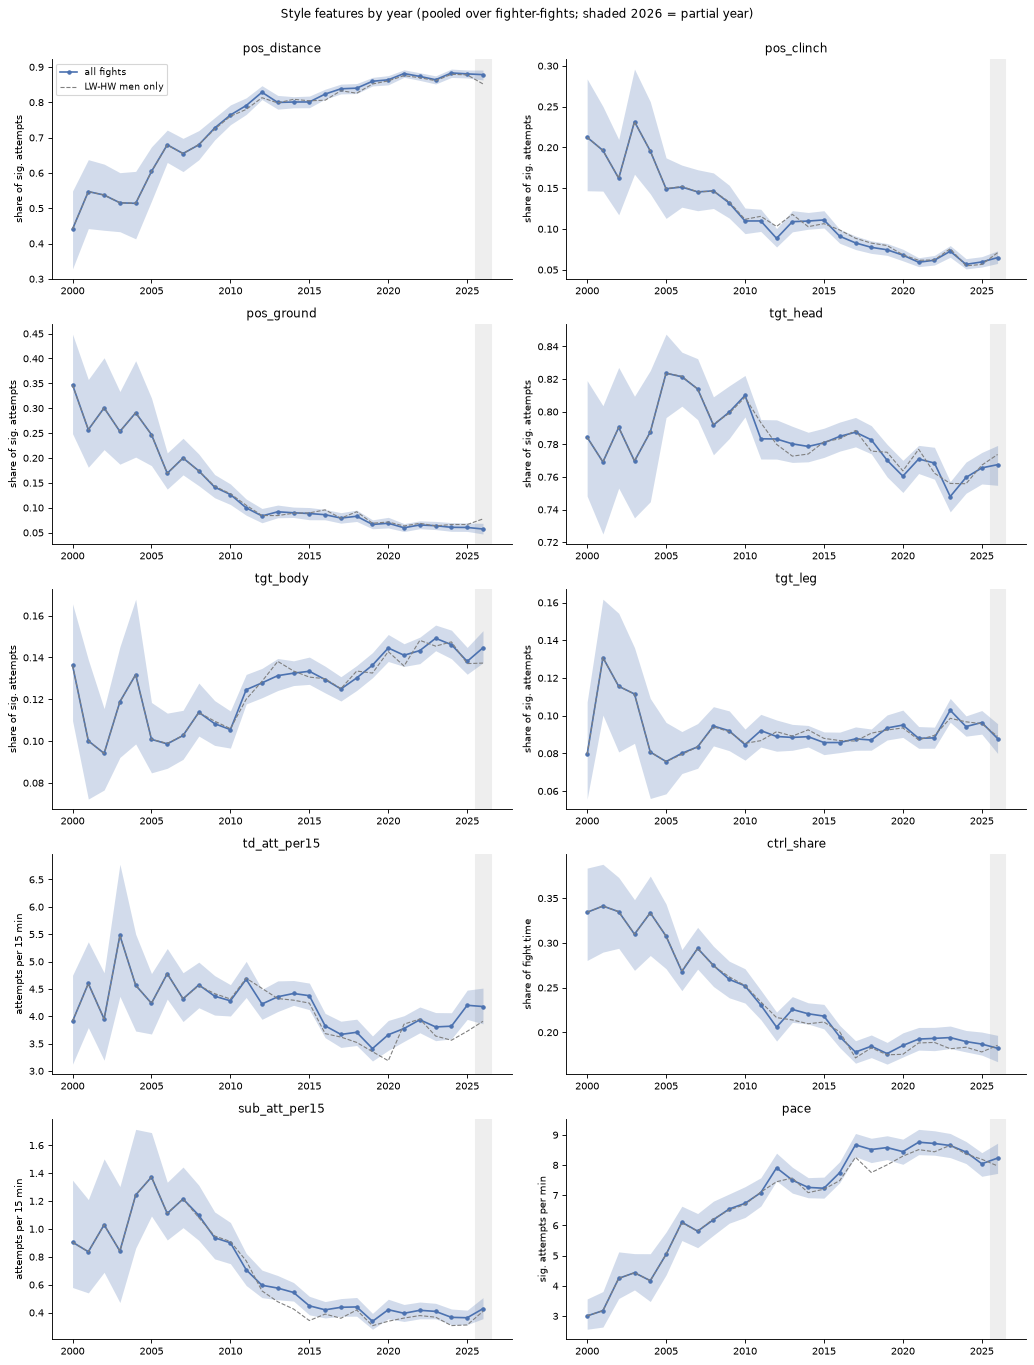

In [3]:
fig, axes = plt.subplots(5, 2, figsize=(13, 17))
for ax, f in zip(axes.flat, F.STYLE_FEATURES):
    t = trend[trend["feature"] == f]
    tc = trend_core[trend_core["feature"] == f]
    ax.fill_between(t["year"], t["lo"], t["hi"], color="#4C72B0", alpha=0.25, lw=0)
    ax.plot(t["year"], t["value"], color="#4C72B0", marker="o", ms=3, label="all fights")
    ax.plot(tc["year"], tc["value"], color="grey", ls="--", lw=1, label="LW-HW men only")
    ax.set_title(f)
    ax.set_ylabel(UNITS.get(f, "share of sig. attempts"))
    ax.axvspan(2025.5, 2026.5, color="#eeeeee", zorder=-1)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Style features by year (pooled over fighter-fights; shaded 2026 = partial year)", y=1.0, fontsize=11)
fig.tight_layout(); plt.show()

## 2. Then and now

Pooled values for 2000–2004 and 2021–2025 (complete years), with the change in absolute and relative terms.

In [4]:
def pooled(fr, years):
    g = fr[fr["year"].between(*years)]
    return pd.Series({f: s * g[n].sum() / g[d].sum() for f, (n, d, s) in DEFS.items()})
early, late = pooled(fights, (2000, 2004)), pooled(fights, (2021, 2025))
tab = pd.DataFrame({"2000-04": early, "2021-25": late, "change": late - early, "relative change": (late / early - 1)})
display(tab.style.format({"2000-04": "{:.3f}", "2021-25": "{:.3f}", "change": "{:+.3f}", "relative change": "{:+.0%}"}))
ec, lc = pooled(core_fights, (2000, 2004)), pooled(core_fights, (2021, 2025))
print("Same comparison, LW-HW men only (relative change):", (lc / ec - 1).map("{:+.0%}".format).to_dict())

,2000-04,2021-25,change,relative change
pos_distance,0.515,0.876,+0.362,+70%
pos_clinch,0.197,0.062,-0.135,-69%
pos_ground,0.288,0.062,-0.226,-79%
tgt_head,0.781,0.763,-0.018,-2%
tgt_body,0.114,0.144,+0.030,+26%
tgt_leg,0.106,0.094,-0.012,-11%
td_att_per15,4.465,3.904,-0.561,-13%
ctrl_share,0.331,0.191,-0.140,-42%
sub_att_per15,0.961,0.389,-0.572,-59%
pace,3.807,8.517,+4.710,+124%


Same comparison, LW-HW men only (relative change): {'pos_distance': '+69%', 'pos_clinch': '-69%', 'pos_ground': '-77%', 'tgt_head': '-2%', 'tgt_body': '+26%', 'tgt_leg': '-12%', 'td_att_per15': '-16%', 'ctrl_share': '-44%', 'sub_att_per15': '-64%', 'pace': '+121%'}


## What the plots show

Descriptive only; these are league-wide pooled rates, not per-fighter averages.

- **Striking volume and range grew steadily.** Pace (significant-strike attempts per fighter-minute) roughly doubled, from about 3–4 in
  2000–04 to about 8.5 since 2020. Most of the rise came by 2017, and it has been flat since. The share of attempts thrown at
  distance rose from about half to almost 90%, mostly before 2012.
- **Clinch and ground striking declined** to a small share (each about 6% of attempts now, against roughly 20% and 29% in 2000–04).
  Control time as a share of fight time fell from about a third to about a fifth, mostly between 2005 and 2017.
- **Submission attempts per 15 minutes fell by more than half**, mostly between 2008 and 2015.
- **Takedown attempts per 15 minutes** changed comparatively little (about −13%), with a dip around 2016–2020. Grappling *attempts* held
  up better than the time spent controlling or striking on the ground.
- **Target mix is the most stable:** head share stayed around 76–82%, and body share drifted up a few points.
- **Not a division-mix effect:** the five men's divisions present throughout (grey dashed) follow nearly the same curves as all fights.
- **Caveat:** fights before ufcstats.com began recording in real time were coded afterwards from video, so some of the early-2000s
  change may reflect recording practice as well as the sport. The data can't separate the two.
- This drift is why the style features used for the axes and clusters are standardized **within era** (`docs/feature_spec.md`).

## 3. Fights per year

The bands are wide in the early years because there were few fights (about 40–80 a year before 2006).

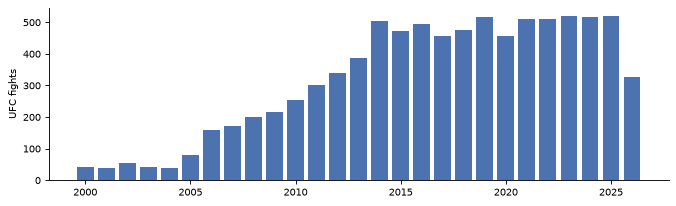

In [5]:
n = trend.drop_duplicates("year")[["year", "fights"]]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(n["year"], n["fights"], color="#4C72B0")
ax.set_ylabel("UFC fights")
plt.show()